# UTA Softball DATA 4380 Project

#### Group Members: Michael Sheehey, Nathan Butler, Franklin Osualaaham, Sarthakkumar Patel, Joseph Uzoigwe

### Research Questions:
#### 1. Which pitch characteristics are associated with successful pitching outcomes?
#### 4. Can we identify different pitching styles based on velocity, spin rate, and ball movement?

In [12]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import missingno as msno

# Locate the CSV file
csv_path = Path("South Dakota State_0466 (1).csv")

# read into pandas datafrrame
df = pd.read_csv(csv_path)

# check load with dimensions and head
print("Dataset shape (rows, cols):", df.shape)
print(df.head())

Dataset shape (rows, cols): (259, 125)
   PitchNo       Date        Time  PAofInning  PitchofPA        Pitcher  \
0      1.0  3/14/2026  3:33:43 PM         1.0        1.0  Kynlee Bowlin   
1      2.0  3/14/2026  3:33:59 PM         1.0        2.0  Kynlee Bowlin   
2      3.0  3/14/2026  3:34:33 PM         1.0        3.0  Kynlee Bowlin   
3      4.0  3/14/2026  3:35:00 PM         2.0        1.0  Kynlee Bowlin   
4      5.0  3/14/2026  3:35:20 PM         2.0        2.0  Kynlee Bowlin   

  PitcherId PitcherThrows  PitcherTeam          Batter  ...  \
0       NaN         Right  Uta fall 25     Bria Riebel  ...   
1       NaN         Right  Uta fall 25     Bria Riebel  ...   
2       NaN         Right  Uta fall 25     Bria Riebel  ...   
3       NaN         Right  Uta fall 25  Akayla Barnard  ...   
4       NaN         Right  Uta fall 25  Akayla Barnard  ...   

  yt_EffectiveBattingSpeed yt_ReleaseAccuracy yt_ZoneAccuracy  yt_SeamLat  \
0                      NaN               high         

#### We can already see we are going to have missing values to deal with and we also see our dataset has a size of 259 rows by 125 columns. We may have to reduce our independent variables going forward.

### We need to separate the observations belonging to UTA vs South Dakota State

In [3]:
# count pitches recorded for each pitching team
team_counts = df["PitcherTeam"].value_counts(dropna=False)

display(team_counts)

PitcherTeam
South dakota state [sou03:2025]    131
Uta fall 25                        128
Name: count, dtype: int64

#### Here we isolate the "PitcherTeam" categorical var which gives us a pandas series and then call the value_counts() method to count how frequently each distinct value shows up (by specifying dropna=False were asking pandas to count our missing team labels as well). Here however, because our counts add to 259 we know that there are no missing labels.

### Lets isolate UTA pitchers

In [4]:
# create a separate df containing only pitches thrown by UTA
uta_df = df.loc[df["PitcherTeam"] == "Uta fall 25"].copy()

# verify dimensions
print("UTA dataset shape:", uta_df.shape)

# ID UTA pitchers and count their pitches, include na vals similar to above cell
pitcher_counts = uta_df["Pitcher"].value_counts(dropna=False)

display(pitcher_counts)

UTA dataset shape: (128, 125)


Pitcher
Maddie Furniss    82
Kynlee Bowlin     46
Name: count, dtype: int64

#### Here we ask pandas to check if each val for PitcherTeam matches Uta fall 25. We then keep every row returning true for that match and copy into uta_df as its own separate dataframe without modifying the original.

#### What we've learned so far is that for UTA we are examining two different pitchers from fall of '25. Maddie Furniss has more recorded pitches compared to Kynlee Bowlin which could create some imbalance issues for us in the future if we want to compare performance. The 128 pitches do not represent different athletes here they represent the two same pitchers all from one game. 

### Lets investigate variable types to understand our dataset better

In [5]:
# We want to analyze types for our variables because it will help us determine
# which statistical tests are appropriate

# count how many cols belong to each data type
dtype_counts = uta_df.dtypes.value_counts()

display(dtype_counts)

# create a table that shows every col and its data type
column_types = pd.DataFrame({
    "Column": uta_df.columns,
    "Data Type": uta_df.dtypes.values
})

display(column_types)

float64    94
str        27
int64       4
Name: count, dtype: int64

,Column,Data Type
0,PitchNo,float64
1,Date,str
2,Time,str
3,PAofInning,float64
4,PitchofPA,float64
...,...,...
120,yt_ReleaseDistance,float64
121,Catcher,str
122,CatcherId,str
123,CatcherTeam,str


#### We can see some oddities like PitchNo stored as a float when they are normally ints. Interestingly this can happen when a numeric column contains missing values because traditional NumPy integer arrays cannot represent NaN (will need to investigate further). We also can see date and time are strings, we may want to convert these to datetime objects. 

### Understanding Missing Data

#### Begin with observed-data analysis. We can evaluate imputation later when we understand patterns and have a justified statistical objective.

In [10]:
# again total UTA pitching observations
n = len(uta_df)

# count missing measurments for each var
missing_count = uta_df.isna().sum()

# count observed measuremnets for each var
observed_count = uta_df.notna().sum()

# calc percent of missing measurements
missing_percent = uta_df.isna().mean() * 100

# Show results in summary df
missing_summary = pd.DataFrame({
    "Observed Count": observed_count,
    "Missing Count": missing_count,
    "Missing Percent": missing_percent
})

# sort by percentage
missing_summary = missing_summary.sort_values(
    by="Missing Percent",
    ascending=False
)

print(f"UTA pitching observations: {n}")

# show 25 vars with most missing data
display(missing_summary.head(50).round(2))

UTA pitching observations: 128


,Observed Count,Missing Count,Missing Percent
PitcherId,0,128,100.00
AutoPitchType,0,128,100.00
Notes,0,128,100.00
PitcherSet,0,128,100.00
LastTrackedDistance,0,128,100.00
yt_SeamLat,0,128,100.00
yt_SeamLong,0,128,100.00
Note,0,128,100.00
CatcherId,0,128,100.00
yt_FSRI,0,128,100.00


#### Sorting in descending order places our most incomplete vars first which will help us spot our problems. We can see groupings of missingness, lets see if that implys the same missing values.

In [11]:
# compare two measurements with equal missing counts
features = ["HitSpinRate", "PositionAt110X"]

# a true indication means the measurement is present
availability = uta_df[features].notna()

# compare which pitches have each measurement
overlap_table = pd.crosstab(
    availability["HitSpinRate"],
    availability["PositionAt110X"]
)

display(overlap_table)

PositionAt110X,False,True
HitSpinRate,,
False,101,4
True,4,19


#### We have 23 observations for each var but they only cross at 19 pitches, we would be unable to pair these two.


### Next we will visualize missing data

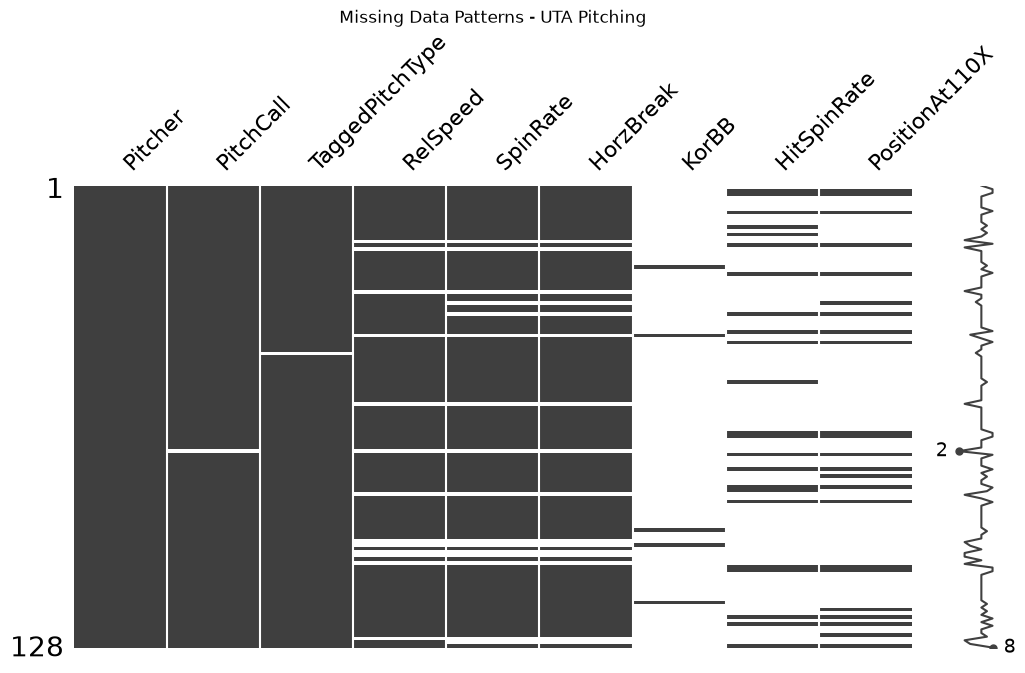

In [14]:
# The selected vars were chosen because at first glance they appear relevent to our research questions
# These vars may be modified in the future

selected_cols = [
    "Pitcher",
    "PitchCall",
    "TaggedPitchType",
    "RelSpeed",
    "SpinRate",
    "HorzBreak",
    "KorBB",
    "HitSpinRate",
    "PositionAt110X"
]

# create a df for missing visuals
missing_df = uta_df[selected_cols].copy()

# ccreate missingness matrix
msno.matrix(missing_df, figsize=(12,6))
plt.title("Missing Data Patterns - UTA Pitching")

plt.show()